## **PHASE 3: MULTI-ASPECT MODEL TRAINING & EVALUATION**

The goal of this phase is to train an aspect-based sentiment classifier using the llm-labeled dataset.

**Model:**
The pipeline use a single shared DistilBERT backbone with seven separate 3-way classification heads (predicting *not mentioned*, *positive*, or *negative* for each of the seven skincare aspects: texture, scent, breakouts, irritation, efficacy, packaging, and value). This multi-head design allows the model to share underlying semantic representations while maintaining independent decision boundaries for each aspect.

**Dataset & Iteration:**
Train straight on the final dataset (skincare_reviews_llm_final_v3.csv). I had to do some extra targeted labeling back in Phase 2 because the first runs didn't catch enough negative irritation and packaging examples.

**Gold-Set Evaluation:**
The trained model is evaluated against the independent, human-annotated gold set created in Phase 2. This ground-truth test set guarantees unbiased validation.

### Step 1: Imports and device check

In [ ]:
# Load required libraries and print whether MPS is available
import torch
from sklearn.model_selection import train_test_split
from transformers import DistilBertTokenizerFast, DistilBertModel
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import random
import numpy as np


print("MPS available:", torch.backends.mps.is_available())

MPS available: True


### Step 2: Load the final labeled dataset and gold set

In [ ]:
# Set seed for reproducibility
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

set_seed()

In [37]:
import pandas as pd

# 1. Load LLM-labeled training data
train_val_df = pd.read_csv("skincare_reviews_llm_final_v3.csv")

# 2. Load human-annotated gold set
gold_df = pd.read_excel("gold_to_label.xlsx") 

print(f"LLM training pool shape: {train_val_df.shape}")
print(f"Human gold set shape: {gold_df.shape}")

LLM training pool shape: (1998, 23)
Human gold set shape: (200, 10)


### Step 3: Map labels to numeric classes

In [ ]:
# Clean and map labels to numeric values for both datasets
ASPECTS = ["texture", "scent", "breakouts", "irritation", "efficacy", "packaging", "value"]
LABEL_MAP = {None: 0, "positive": 1, "negative": 2, "P": 1, "N": 2}

def clean_and_map(series):
    valid = series.where(series.isin(["positive", "negative", "P", "N"]), None)
    return valid.map(LABEL_MAP)

for aspect in ASPECTS:
    train_val_df[f"{aspect}_label"] = clean_and_map(train_val_df[aspect])
    gold_df[f"{aspect}_label"] = clean_and_map(gold_df[aspect])

label_cols = [f"{aspect}_label" for aspect in ASPECTS]
print("Label columns:", label_cols)


Label columns: ['texture_label', 'scent_label', 'breakouts_label', 'irritation_label', 'efficacy_label', 'packaging_label', 'value_label']


In [ ]:
# Check for missing values in the label columns of both datasets
print("Missing values in train_val_df:")
print(train_val_df[label_cols].isna().sum())
print("Missing values in gold_df:")
print(gold_df[label_cols].isna().sum())

Missing values in train_val_df:
texture_label       0
scent_label         0
breakouts_label     0
irritation_label    0
efficacy_label      0
packaging_label     0
value_label         0
dtype: int64
Missing values in gold_df:
texture_label       0
scent_label         0
breakouts_label     0
irritation_label    0
efficacy_label      0
packaging_label     0
value_label         0
dtype: int64


### Step 4: Class distribution per aspect

In [ ]:
# Compute and print class distribution counts per aspect
label_names = {0: "Not mentioned", 1: "Positive", 2: "Negative"}

print("Train/Validation label distribution for aspect:")
for aspect in ASPECTS:
    print(f"\n{aspect.upper()}")
    counts = train_val_df[f"{aspect}_label"].value_counts().sort_index()

    for label in [0, 1, 2]:
        print(f"{label_names[label]:15}: {counts.get(label, 0)}")




Train/Validation label distribution for aspect:

TEXTURE
Not mentioned  : 1035
Positive       : 749
Negative       : 214

SCENT
Not mentioned  : 1460
Positive       : 439
Negative       : 99

BREAKOUTS
Not mentioned  : 1734
Positive       : 149
Negative       : 115

IRRITATION
Not mentioned  : 1569
Positive       : 197
Negative       : 232

EFFICACY
Not mentioned  : 561
Positive       : 1282
Negative       : 155

PACKAGING
Not mentioned  : 1600
Positive       : 157
Negative       : 241

VALUE
Not mentioned  : 1657
Positive       : 137
Negative       : 204


In [ ]:
# Compute and print class distribution counts per aspect
print("Gold label distribution for aspect:")
for aspect in ASPECTS:
    print(f"\n{aspect.upper()}")
    counts = gold_df[f"{aspect}_label"].value_counts().sort_index()

    for label in [0, 1, 2]:
        print(f"{label_names[label]:15}: {counts.get(label, 0)}")

Gold label distribution for aspect:

TEXTURE
Not mentioned  : 112
Positive       : 74
Negative       : 14

SCENT
Not mentioned  : 147
Positive       : 41
Negative       : 12

BREAKOUTS
Not mentioned  : 175
Positive       : 16
Negative       : 9

IRRITATION
Not mentioned  : 165
Positive       : 26
Negative       : 9

EFFICACY
Not mentioned  : 35
Positive       : 148
Negative       : 17

PACKAGING
Not mentioned  : 177
Positive       : 16
Negative       : 7

VALUE
Not mentioned  : 171
Positive       : 19
Negative       : 10


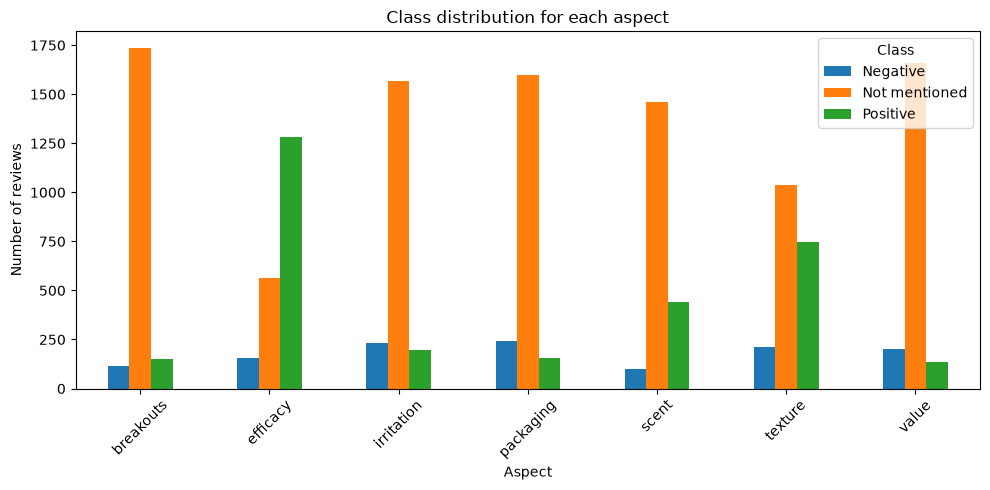

In [ ]:
# Assemble a DataFrame for plotting and display a bar chart of class counts
plot_data = []

for aspect in ASPECTS:
    counts = train_val_df[f"{aspect}_label"].value_counts().sort_index()

    for label in [0,1,2]:
        plot_data.append({
            "Aspect": aspect,
            "Class": label_names[label],
            "Count": counts.get(label,0)
        })

plot_df = pd.DataFrame(plot_data)

pivot = plot_df.pivot(index="Aspect", columns="Class", values="Count")

pivot.plot(kind="bar", figsize=(10,5))

plt.ylabel("Number of reviews")
plt.title("Class distribution for each aspect")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 5: Prepare train, validation and test set

In [ ]:
# Split LLM data into Train (85%) and Validation (15%)
train_df, val_df = train_test_split(train_val_df, test_size=0.15, random_state=42)

# Test set is strictly human gold set
test_df = gold_df

# Print the number of reviews in each dataset
print(f"Train: {len(train_df)} reviews")
print(f"Validation: {len(val_df)} reviews")
print(f"Test (Human Gold Set): {len(test_df)} reviews")

# Compare the class distributions of the train and test datasets for each aspect
label_names = {0: "Not mentioned", 1: "Positive", 2: "Negative"}

for aspect in ASPECTS:
    train_dist = train_df[f"{aspect}_label"].value_counts(normalize=True).sort_index()
    test_dist = test_df[f"{aspect}_label"].value_counts(normalize=True).sort_index()

    comparison = pd.DataFrame({
        "Train": train_dist,
        "Test": test_dist
    }).fillna(0)

    comparison.index = [label_names[i] for i in comparison.index]

    print(f"\n=== {aspect.upper()} ===")
    print(comparison.round(3))



Train: 1698 reviews
Validation: 300 reviews
Test (Human Gold Set): 200 reviews

=== TEXTURE ===
               Train  Test
Not mentioned  0.515  0.56
Positive       0.375  0.37
Negative       0.110  0.07

=== SCENT ===
               Train   Test
Not mentioned  0.730  0.735
Positive       0.218  0.205
Negative       0.052  0.060

=== BREAKOUTS ===
               Train   Test
Not mentioned  0.869  0.875
Positive       0.073  0.080
Negative       0.058  0.045

=== IRRITATION ===
               Train   Test
Not mentioned  0.786  0.825
Positive       0.095  0.130
Negative       0.119  0.045

=== EFFICACY ===
               Train   Test
Not mentioned  0.280  0.175
Positive       0.641  0.740
Negative       0.078  0.085

=== PACKAGING ===
               Train   Test
Not mentioned  0.798  0.885
Positive       0.081  0.080
Negative       0.121  0.035

=== VALUE ===
               Train   Test
Not mentioned  0.831  0.855
Positive       0.068  0.095
Negative       0.101  0.050


Class distributions for all seven aspects remained similar between train and test
(differences generally within a few percentage points) — the random split didn't need
manual stratification.

### Step 6: Tokenization setup

In [ ]:
# Select device
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

# Load tokenizer 
MODEL_NAME = "distilbert-base-uncased"
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

# Use the full cleaned dataset
df_full = pd.read_csv("skincare_reviews_clean.csv", usecols=["review_text"])

# Check token lengths for a sample of reviews to determine truncation needs
n = min(20000, len(df_full))
sample_texts = df_full["review_text"].sample(n, random_state=42).astype(str).tolist()

lengths = np.array([len(x) for x in tokenizer(sample_texts, truncation=False)["input_ids"]])

print("Token length percentiles (50/90/95/99/100):", np.percentile(lengths, [50, 90, 95, 99, 100]))
print(f"Share truncated at 256: {(lengths > 256).mean():.2%}")
print(f"Share truncated at 384: {(lengths > 384).mean():.2%}")


Using device: mps


Token indices sequence length is longer than the specified maximum sequence length for this model (577 > 512). Running this sequence through the model will result in indexing errors


Token length percentiles (50/90/95/99/100): [ 64. 142. 179. 281. 592.]
Share truncated at 256: 1.41%
Share truncated at 384: 0.23%


In [45]:
# Set MAX_LEN based on the data and define aspects

MAX_LEN = 256  # Measured on a 20k sample of the full dataset:
               # median 64, 95th pct 179, 99th pct 281 tokens; 1.41% of reviews exceed 256
               # and are truncated (0.23% exceed 384)

ASPECTS = ["texture", "scent", "breakouts", "irritation", "efficacy", "packaging", "value"]

### Step 7: Create custom Dataset class that tokenizes text and returns all 7 aspect labels together

In [ ]:
# Define a custom DataSet class that converts raw data into structured, batchable PyTorch tensors that neural networks (like DistilBERT) can process
# It tokenizes the review text and returns tensors for input_ids, attention_mask, and labels for each aspect.
class AspectReviewDataset(Dataset):

    def __init__(self, df, tokenizer, aspects, max_len=256):
        # review texts as a list
        self.texts = df["review_text"].tolist()

        # Store labels for each aspect
        self.labels = {
            aspect: df[f"{aspect}_label"].tolist()
            for aspect in aspects
        }

        self.tokenizer = tokenizer
        self.aspects = aspects
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        # Tokenize one review and convert it into model integers IDs inputs
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,              # Cut text if it is longer than max_len
            padding="max_length",         # Pad shorter texts to max_len
            max_length=self.max_len,      # Maximum number of tokens
            return_tensors="pt"           # Return PyTorch tensors
        )

        # Create the input dictionary for the model
        item = {
            # Remove the extra batch dimension. Hugging Face's tokenizer adds a 1-element batch dimension by default (e.g., shape [1, 256]). 
            "input_ids": encoding["input_ids"].squeeze(0),

            # Shows which tokens are real text vs padding. A sequence of 1s and 0s (1 for real word tokens, 0 for padding tokens). 
            # DistilBERT uses this mask to ignore padding during attention calculations
            "attention_mask": encoding["attention_mask"].squeeze(0),
        }

        # Add the label for each aspect. It loops over all 7 aspects and fethces the integer label for the current review (idx) and converts it into a PyTorch tensor. 
        for aspect in self.aspects:
            item[f"{aspect}_label"] = torch.tensor(
                self.labels[aspect][idx],
                dtype=torch.long
            )

        # Returns a single dictionary containing the tokenized review representation and all 7 aspect labels, ready to be passed directly into DistilBERT
        return item

### Step 8: Define MultiAspectClassifier model — shared DistilBERT backbone & one linear head per aspect

In [ ]:
# Multi-aspect classifier using DistilBERT with one classification head for each aspect
class MultiAspectClassifier(nn.Module):

    def __init__(self, model_name, aspects, num_classes=3, dropout=0.3):
        super().__init__()

        # Loads the pre-trained DistilBERT weights
        self.bert = DistilBertModel.from_pretrained(model_name)

        # Save the list of aspects
        self.aspects = aspects

        # Get the size of DistilBERT's output representation (768 for distilbert-base-uncased)
        hidden_size = self.bert.config.hidden_size

        # reduce overfitting during training
        self.dropout = nn.Dropout(dropout)

        # Create one classification head for each aspect
        # Each head predicts 3 classes:
        # 0 = Not mentioned, 1 = Positive, 2 = Negative
        self.heads = nn.ModuleDict({
            aspect: nn.Linear(hidden_size, num_classes)
            for aspect in aspects
        })

    def forward(self, input_ids, attention_mask):

        # Feeds batch token IDs and attention masks through DistilBERT's Transformer layers (returns last_hidden_state of shape (batch_size, sequence_length, 768))
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Take the representation of the first token ([CLS] position) (Because self-attention allows the [CLS] token to attend to all other words in the review, outputs.last_hidden_state[:, 0] represents the entire review
        pooled = outputs.last_hidden_state[:, 0]

        # Apply dropout before classification
        pooled = self.dropout(pooled)

        # Aspect-Specific Logit Prediction.
        # Evaluates the pooled review representation vector independently through each of the 7 aspect heads inside self.heads
        logits = {
            aspect: self.heads[aspect](pooled)
            for aspect in self.aspects
        }

        # Return values for each aspect's sentiment prediction as a dictionary of logits. 
        # Each key is an aspect name, and the value is a tensor of shape (batch_size, num_classes) containing the raw scores for each class
        return logits

### Step 9: Build datasets/loaders and sanity-check the model's output shapes

In [ ]:
# Datasets and data loaders for train/val/test sets. The DataLoader will handle batching, shuffling, and parallel loading of the data during training and evaluation.
set_seed()
train_dataset = AspectReviewDataset(train_df, tokenizer, ASPECTS, max_len=MAX_LEN)
val_dataset = AspectReviewDataset(val_df, tokenizer, ASPECTS, max_len=MAX_LEN)
test_dataset = AspectReviewDataset(test_df, tokenizer, ASPECTS, max_len=MAX_LEN)

# Note for report -> n the original BERT / DistilBERT literature (Devlin et al., Sanh et al.), the authors recommend batch sizes of 16 or 32 for fine-tuning tasks.
# Smaller models fine-tuned on sentence/paragraph-level text classification perform most reliably within this narrow range.
BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 107
Val batches: 19


In [ ]:
# Create model, run one batch through it as a quick sanity check of shapes
model = MultiAspectClassifier(MODEL_NAME, ASPECTS).to(DEVICE)

# Quick sanity check: run one batch through the model
batch = next(iter(train_loader))
input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)

with torch.no_grad():
    logits = model(input_ids, attention_mask)

for aspect, out in logits.items():
    print(aspect, out.shape)  # should be [batch_size, 3] for each aspect

texture torch.Size([16, 3])
scent torch.Size([16, 3])
breakouts torch.Size([16, 3])
irritation torch.Size([16, 3])
efficacy torch.Size([16, 3])
packaging torch.Size([16, 3])
value torch.Size([16, 3])


### Step 10: Define loss, optimizer, and evaluation function

In [ ]:
# Toptimizer, loss, compute_loss helper, and evaluation function
from torch.optim import AdamW
from sklearn.metrics import f1_score
import numpy as np

# CrossEntropyLoss is suitable for multi-class classification tasks(compute the loss between the predicted logits and the true labels for each aspect)
criterion = nn.CrossEntropyLoss()

# Unlike standard Adam, AdamW decouples weight decay regularization from gradient updates, preventing model parameters from growing too large and reducing overfitting.
optimizer = AdamW(model.parameters(), lr=2e-5)

EPOCHS = 100

# Implements Early Stopping. If the validation macro F1 score fails to improve after 2 consecutive epochs, training terminates early to prevent overfitting.
best_val_f1 = 0
patience = 2
counter = 0

# Multi-Task Loss Summing: The compute_loss function calculates the total loss across all aspects by summing the individual CrossEntropyLoss values for each aspect (model to learns from all aspects simultaneously)
def compute_loss(logits, batch):
    total_loss = 0
    for aspect in ASPECTS:
        labels = batch[f"{aspect}_label"].to(DEVICE)
        total_loss += criterion(logits[aspect], labels)
    return total_loss

# Model evaluation function that computes average loss and macro F1 scores for each aspect on a given dataset loader (train, validation, or test).
def evaluate(model, loader):
    model.eval()
    all_preds = {aspect: [] for aspect in ASPECTS}
    all_labels = {aspect: [] for aspect in ASPECTS}
    total_loss = 0

    with torch.no_grad(): 
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            logits = model(input_ids, attention_mask)

            total_loss += compute_loss(logits, batch).item()

            for aspect in ASPECTS:
                # Selects the class index with the highest logit score for each review in the batch.
                preds = torch.argmax(logits[aspect], dim=1).cpu().numpy()

                # Converts predictions to NumPy arrays and appends them to all_preds and all_labels lists for each aspect across the entire dataset split
                labels = batch[f"{aspect}_label"].numpy()
                all_preds[aspect].extend(preds)
                all_labels[aspect].extend(labels)

    # Compute average loss across all batches in the loader
    avg_loss = total_loss / len(loader)

    # Compute macro F1 score for each aspect. Macro F1 treats all classes equally, regardless of their frequency, making it suitable for imbalanced datasets.   
    macro_f1 = {
        aspect: f1_score(
            all_labels[aspect],
            all_preds[aspect],
            average="macro",
            zero_division=0 # Prevents runtime errors if a minority class receives zero predicted instances during early evaluation steps
        )
        for aspect in ASPECTS
    }

    return avg_loss, macro_f1, all_preds, all_labels

### Step 11: Train, with early stopping and checkpointing

Saves the best checkpoint (by validation macro F1) to `aspect_sentiment_model_final.pt`, and
stops automatically if validation F1 doesn't improve for 2 consecutive epochs.

In [ ]:
# Training loop with validation, early stopping, and checkpoint saving
for epoch in range(EPOCHS):
    model.train()                       
    train_loss = 0                      

    for batch in train_loader:
        optimizer.zero_grad()                                     
        input_ids = batch["input_ids"].to(DEVICE)                 # Move input data to the selected device
        attention_mask = batch["attention_mask"].to(DEVICE)
        logits = model(input_ids, attention_mask)                 # Runs the batch through the model and eturns predictions for all 7 aspects
        loss = compute_loss(logits, batch)                        # Calculate the total loss
        loss.backward()                                           # Calculate gradients
        optimizer.step()                                          # Update model parameters based on gradients
        train_loss += loss.item()                                 # Accumulate the loss for this batch to compute the average later

    train_loss /= len(train_loader)                       # Calculate average training loss for the epoch           
    val_loss, val_f1, _, _ = evaluate(model, val_loader)  # Evaluate the model on validation data
    val_macro_f1 = np.mean(list(val_f1.values()))         # Calculate the average F1 score across all aspects

    print(f"Epoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Macro F1: {val_macro_f1:.4f}")

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1       # Save the new best F1 score
        counter = 0                      # Reset the early-stopping counter

        # Save the best model
        torch.save({
            "model_state_dict": model.state_dict(),
            "tokenizer": MODEL_NAME,
            "aspects": ASPECTS
        }, "aspect_sentiment_model_final.pt")
        print("Best model saved.")

    else:
        counter += 1                    # No improvement → increase the patience counter

    if counter >= patience:             # Stop training if the model hasn't improved for too many epochs
        print("Early stopping.")
        break

Epoch 1/100
Train Loss: 2.7808
Val Loss: 2.9243
Val Macro F1: 0.5509
Best model saved.
Epoch 2/100
Train Loss: 2.2823
Val Loss: 2.7057
Val Macro F1: 0.6578
Best model saved.
Epoch 3/100
Train Loss: 1.8160
Val Loss: 2.6455
Val Macro F1: 0.6890
Best model saved.
Epoch 4/100
Train Loss: 1.4434
Val Loss: 2.5614
Val Macro F1: 0.7082
Best model saved.
Epoch 5/100
Train Loss: 1.1944
Val Loss: 2.6485
Val Macro F1: 0.7034
Epoch 6/100
Train Loss: 0.9358
Val Loss: 2.6271
Val Macro F1: 0.7314
Best model saved.
Epoch 7/100
Train Loss: 0.7618
Val Loss: 2.7035
Val Macro F1: 0.7144
Epoch 8/100
Train Loss: 0.6074
Val Loss: 2.8221
Val Macro F1: 0.7394
Best model saved.
Epoch 9/100
Train Loss: 0.5364
Val Loss: 3.0005
Val Macro F1: 0.7496
Best model saved.
Epoch 10/100
Train Loss: 0.4546
Val Loss: 2.8337
Val Macro F1: 0.7350
Epoch 11/100
Train Loss: 0.3655
Val Loss: 2.8768
Val Macro F1: 0.7441
Early stopping.


### Step 12: Evaluate the best model checkpoint on the human annotated data

Accuracy could look good just by predicting "Not mentioned" often
F1(recall, precision) helps evaluate each class, while macro F1 prevents the large class from hiding poor performance on the smaller classes

- **F1 score** - combines precision and recall into one score. Useful when classes are imbalanced like in this case.
- **Precision** - Of the things I predicted as Positive, how many were actually Positive?
- **Recall** - Of the actual Positive examples, how many did I find?
- **Macro F1** - calculates F1 separately for each class and then gives every class equal weight.

In [ ]:
# Load the saved best model checkpoint, evaluate on the test set, and print the final metrics
checkpoint = torch.load(
    "aspect_sentiment_model_final.pt",
    map_location=DEVICE                                 
)
model.load_state_dict(checkpoint["model_state_dict"])   # Restore the trained model weights from the checkpoint
model.eval()                                            

# Run the model on the test dataset (return test loss, F1 scores, predictions, and true labels)
test_loss, test_f1, test_preds, test_labels = evaluate(
    model,
    test_loader
)

print(f"Test Loss: {test_loss:.4f}")                   # Print the overall test loss
print("Test F1 scores per aspect:")                    # Print the F1 score for each aspect
for aspect, score in test_f1.items():
    print(f"{aspect:12} {score:.3f}")

Test Loss: 2.5203
Test F1 scores per aspect:
texture      0.635
scent        0.780
breakouts    0.805
irritation   0.805
efficacy     0.615
packaging    0.756
value        0.805


### Step 13: Create per-aspect Macro F1 chart

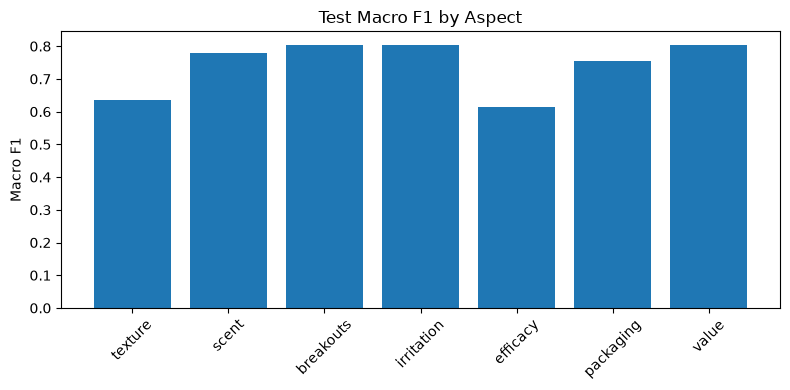

In [ ]:
# Plot a bar chart of test Macro F1 by aspect
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.bar(test_f1.keys(), test_f1.values())

plt.ylabel("Macro F1")
plt.title("Test Macro F1 by Aspect")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 14: Full classification report per aspect (precision/recall/F1 by class)

|        F1 | Rough interpretation |
| --------: | -------------------- |
|    < 0.50 | Poor                 |
| 0.50–0.70 | Moderate             |
| 0.70–0.80 | Good                 |
| 0.80–0.90 | Very good            |
|    > 0.90 | Excellent            |


In [56]:

for aspect in ASPECTS:
    print(f"\n{'='*20} {aspect.upper()} {'='*20}")

    print(classification_report(
        test_labels[aspect],
        test_preds[aspect],
        target_names=["Not mentioned","Positive","Negative"],
        zero_division=0
    ))


==================== TEXTURE ====================
               precision    recall  f1-score   support

Not mentioned       0.97      0.54      0.70       112
     Positive       0.56      0.96      0.71        74
     Negative       0.60      0.43      0.50        14

     accuracy                           0.69       200
    macro avg       0.71      0.64      0.63       200
 weighted avg       0.79      0.69      0.69       200


==================== SCENT ====================
               precision    recall  f1-score   support

Not mentioned       0.98      0.99      0.98       147
     Positive       0.86      0.90      0.88        41
     Negative       0.56      0.42      0.48        12

     accuracy                           0.94       200
    macro avg       0.80      0.77      0.78       200
 weighted avg       0.93      0.94      0.93       200


==================== BREAKOUTS ====================
               precision    recall  f1-score   support

Not mentioned  

### Step 15: Summary table and chart sorted by Macro F1

In [ ]:
# Summary table of Macro F1 scores per aspect
summary = pd.DataFrame({
    "Aspect": list(test_f1.keys()),
    "Macro F1": list(test_f1.values())
})

summary = summary.sort_values("Macro F1", ascending=False)

summary

,Aspect,Macro F1
6,value,0.805128
3,irritation,0.804913
2,breakouts,0.804568
1,scent,0.780065
5,packaging,0.755512
0,texture,0.634537
4,efficacy,0.614955


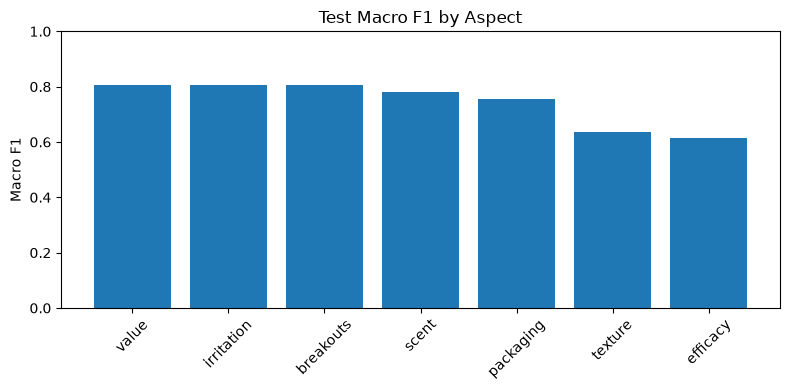

In [ ]:
# Plot the sorted Macro F1 summary by aspect
plt.figure(figsize=(8,4))
plt.bar(summary["Aspect"], summary["Macro F1"])
plt.ylim(0,1)
plt.ylabel("Macro F1")
plt.title("Test Macro F1 by Aspect")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Summary of Phase 3: Training & Gold-Set Evaluation

### What I did in this phase
In this notebook, I trained my multi-aspect sentiment model using a shared **DistilBERT** backbone with 7 separate classification heads (one for each aspect: texture, scent, breakouts, irritation, efficacy, packaging, and value). Each head predicts three classes: *not mentioned*, *positive*, or *negative*. 

Instead of relying on a random split of LLM-labeled data for testing, I plugged in my **human-annotated gold set** as my final test set. This was a super important choice because it means my final evaluation measures how well the model actually performs against true human judgment, rather than just testing how well it agrees with another AI.

### Training strategy & choices
* **Loss & Optimization:** I optimized using cross-entropy loss summed across all 7 aspect heads with the `AdamW` optimizer.
* **Model Selection:** I saved checkpoints based on the validation **Macro F1 score** (rather than validation loss)
* **Early Stopping:** I used patience to prevent overfitting.

### Final Test Results (Human Gold Set Evaluation)
When running my best saved model against the human gold set, I got the following Macro F1 scores per aspect:

* **Breakouts:** 0.805
* **Irritation:** 0.805
* **Value:** 0.805
* **Scent:** 0.780
* **Packaging:** 0.756
* **Texture:** 0.635
* **Efficacy:** 0.615

### Takeaways & Reflections
* **Targeted labeling worked:** Seeing **irritation** hit an F1 of 0.805 is a massive win. It proves that the extra data iteration I did in Phase 2 to fix the lack of negative samples actually paid off on real human data.
* **Where the model struggles:** Texture and efficacy are a bit lower (around 0.61–0.63). Skincare reviews can be really nuanced here—people often write descriptive text about how a product feels or state delayed results ("it took a month to work"), which makes it harder to cleanly separate positive, negative, and neutral sentiments.
* **Overall takeaway:** Hitting 0.75+ to 0.80+ F1 scores across most aspects against independent human annotations gives me enough confidence to run inference on the full dataset.